# Sulpak.kg electronics catalog: prices, availability and discounts

**Question:** what does the biggest electronics retailer in Kyrgyzstan actually sell, at what prices, how much of the catalog is in stock, and where are the real discounts?

**Data:** 1,937 product listings in 7 categories scraped from the public catalog of [sulpak.kg](https://www.sulpak.kg) on **19 Nov 2026** (`scraper/sulpak_scraper.py`). One snapshot, so this is a picture of one day, not a price history.

Contents: 1. Data · 2. Availability · 3. Prices · 4. Discounts · 5. Smartphones: what a brand costs · 6. Laptops · 7. Reviews · 8. Conclusions

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
import matplotlib.pyplot as plt
import charts
from clean import clean, load_raw

pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
pd.options.display.float_format = '{:,.1f}'.format

raw = load_raw(__import__('pathlib').Path('../data/raw/sulpak_2026-11-19.json'))
df = clean(raw)
print(f'{len(raw):,} raw listings -> {len(df):,} rows, {df.shape[1]} columns')

1,937 raw listings -> 1,937 rows, 33 columns


## 1. Data

Each listing card gives name, brand, price, old price (if discounted), stars, review count, availability label and a short spec line. Cleaning (`src/clean.py`):

* `data-price="0"` means **out of stock**: those prices are set to missing and the listing is flagged, not dropped.
* No availability label on a priced card means it can be ordered online (warehouse stock), labelled *Available to order*.
* 0 stars on a card means *no reviews yet*, not a 0-star rating.
* Specs such as RAM, storage, battery, fridge volume and washer load are parsed into numeric columns.
* "Комплект ..." listings are shop **bundles** (phone + gift) and are flagged separately.

In [2]:
summary = df.groupby('category_en').agg(listings=('code', 'size'), in_stock=('in_stock', 'mean'),
                                        bundles=('product_type', lambda s: (s == 'Bundle').sum()),
                                        brands=('brand', 'nunique'))
summary['in_stock'] = (summary['in_stock'] * 100).round(0).astype(int).astype(str) + '%'
summary.sort_values('listings', ascending=False)

,listings,in_stock,bundles,brands
category_en,,,,
Smartphones,645,60%,218,13
Laptops,471,61%,2,15
Headphones,322,38%,29,33
Smartwatches,141,67%,0,10
Fridges,129,95%,2,14
Tablets,125,42%,19,9
Washing machines,104,84%,7,14


In [3]:
# missing values in the main columns (price is missing exactly for out-of-stock listings)
df[['price', 'old_price', 'rating', 'ram_gb', 'storage_gb']].isna().sum().to_frame('missing')

,missing
price,781
old_price,1721
rating,1245
ram_gb,762
storage_gb,857


## 2. Availability

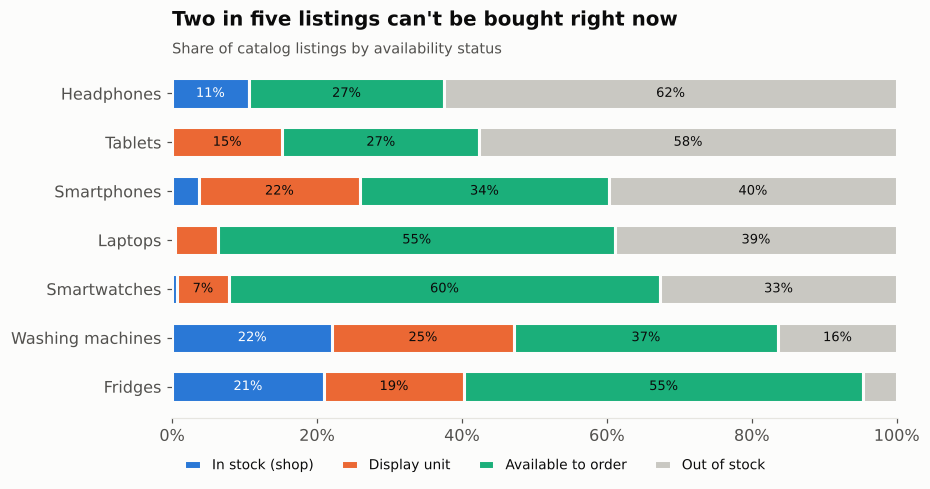

availability_en,Available to order,Display unit,In stock (shop),Out of stock,All
category_en,,,,,
Fridges,71,25,27,6,129
Headphones,87,0,34,201,322
Laptops,258,28,2,183,471
Smartphones,222,143,24,256,645
Smartwatches,84,10,1,46,141
Tablets,34,19,0,72,125
Washing machines,38,26,23,17,104
All,794,251,111,781,1937


In [4]:
charts.availability(df); plt.show()
pd.crosstab(df.category_en, df.availability_en, margins=True)

In [5]:
oos = 1 - df.in_stock.mean()
bundles = df[df.product_type == 'Bundle']
print(f'Out of stock overall: {oos:.0%} of listings')
print(f'Bundles: {len(bundles)} listings, {bundles.in_stock.sum()} of them in stock')

Out of stock overall: 40% of listings
Bundles: 277 listings, 0 of them in stock


**Finding.** About **40% of the catalog cannot be bought today**. Headphones (62% out of stock) and tablets (58%) are the worst; fridges (5%) and washing machines (16%) are almost fully available. All 277 "bundle" listings are out of stock: old promotions stay in the catalog after they end. For a shopper the site looks bigger than the shelf.

## 3. Prices

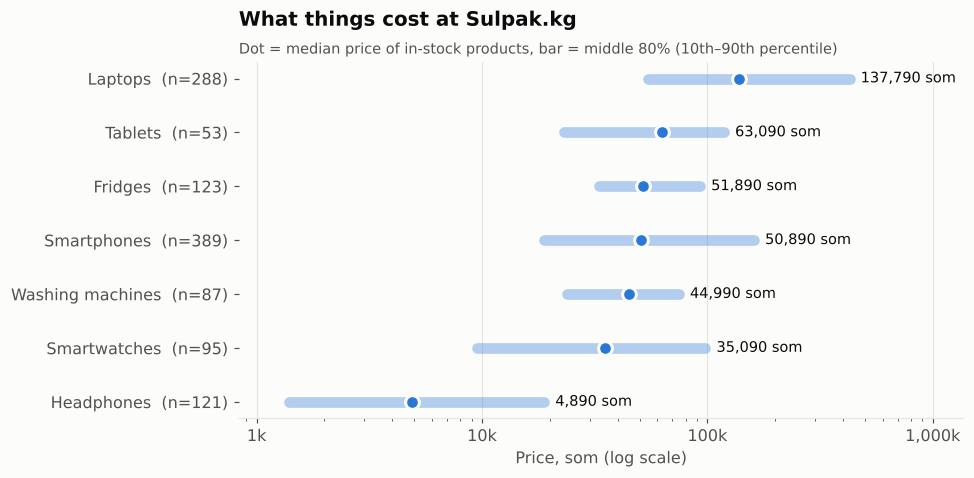

,count,min,10%,50%,90%,max
category_en,,,,,,
Fridges,123.0,"10,690.0","33,090.0","51,890.0","92,830.0","160,390.0"
Headphones,121.0,290.0,"1,390.0","4,890.0","18,890.0","71,390.0"
Laptops,288.0,"35,890.0","54,640.0","137,790.0","427,690.0","860,790.0"
Smartphones,389.0,"11,390.0","18,890.0","50,890.0","160,990.0","429,090.0"
Smartwatches,95.0,"4,790.0","9,490.0","35,090.0","97,990.0","180,990.0"
Tablets,53.0,"7,590.0","23,070.0","63,090.0","118,490.0","168,890.0"
Washing machines,87.0,"19,690.0","23,950.0","44,990.0","74,730.0","188,690.0"


In [6]:
charts.price_ranges(df); plt.show()
s = df[df.in_stock]
s.groupby('category_en')['price'].describe(percentiles=[.1, .5, .9])[['count', 'min', '10%', '50%', '90%', 'max']]

**Finding.** The spread inside a category is wider than between categories. The middle 80% of laptops runs from ~55k to ~430k som (8×), while a typical fridge, smartphone and washing machine all cost about the same, 45–52k som.

## 4. Discounts

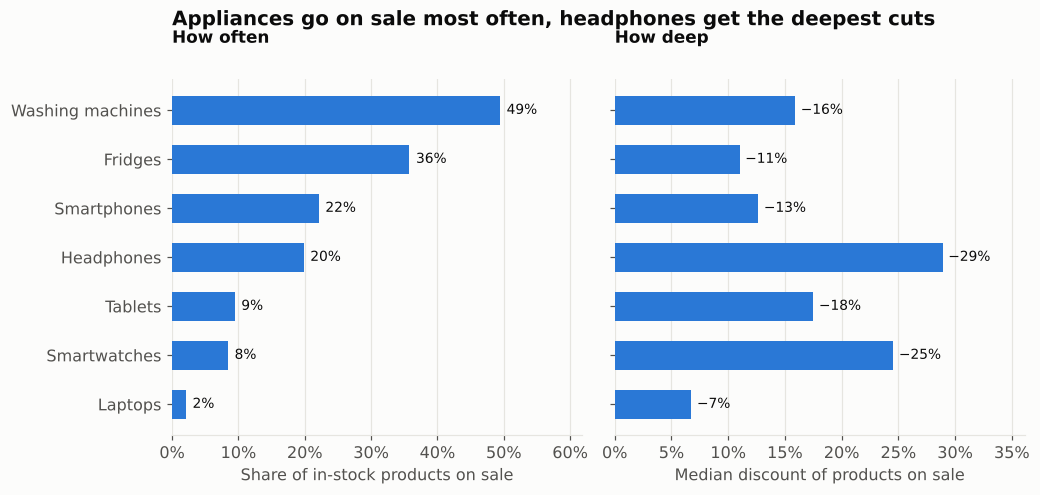

,count,mean,50%,max
category_en,,,,
Fridges,44.0,14.9,11.0,41.8
Headphones,24.0,33.1,28.9,60.5
Laptops,6.0,7.4,6.8,9.7
Smartphones,86.0,13.5,12.7,46.3
Smartwatches,8.0,24.4,24.6,43.9
Tablets,5.0,22.6,17.5,40.1
Washing machines,43.0,19.2,15.9,46.3


In [7]:
charts.discounts(df); plt.show()
on_sale = df[df.on_sale]
on_sale.groupby('category_en')['discount_pct'].describe()[['count', 'mean', '50%', 'max']]

In [8]:
# where the money is: largest discounts in som
on_sale.nlargest(10, 'discount_kgs')[['category_en', 'name', 'price', 'old_price', 'discount_kgs', 'discount_pct']]

,category_en,name,price,old_price,discount_kgs,discount_pct
1720,Fridges,Холодильник Haier HB18FGSAAARU,"156,990.0","269,890.0","112,900.0",41.8
164,Smartphones,Смартфон Samsung Galaxy S25 Ultra 12/256GB Tit...,"122,690.0","169,890.0","47,200.0",27.8
3,Smartphones,Смартфон Samsung Galaxy S26 Ultra 12/256GB Black,"122,690.0","166,090.0","43,400.0",26.1
1876,Washing machines,Стиральная машина Haier HW90-BP14959,"44,590.0","83,090.0","38,500.0",46.3
1875,Washing machines,Стиральная машина Haier HW105-BP14406S,"58,490.0","92,590.0","34,100.0",36.8
1866,Washing machines,Стиральная машина Haier HW80-B14979,"47,190.0","81,190.0","34,000.0",41.9
40,Smartphones,Смартфон Samsung Galaxy S25 12/128GB Navy,"77,390.0","109,490.0","32,100.0",29.3
1725,Fridges,Холодильник Haier C4F740CBXGU1,"70,490.0","101,990.0","31,500.0",30.9
1863,Washing machines,Стиральная машина с сушкой Haier HWD70-BP14929A,"51,890.0","81,190.0","29,300.0",36.1
1751,Fridges,Холодильник Haier C4F640CFMRGU1,"58,490.0","86,890.0","28,400.0",32.7


In [9]:
# which brands discount most often (in-stock products, brands with 10+ listings)
s.groupby('brand').agg(n=('code', 'size'), on_sale=('on_sale', 'mean'), median_discount=('discount_pct', 'median')) \
 .query('n >= 10').sort_values('on_sale', ascending=False).head(10)

,n,on_sale,median_discount
brand,,,
ARG,37,0.6,25.0
Haier,46,0.5,17.3
LG,38,0.5,5.9
Logitech,10,0.4,15.8
Samsung,141,0.3,14.2
Vivo,49,0.2,9.2
OPPO,48,0.2,13.7
HONOR,79,0.2,12.3
Apple,190,0.1,11.9


**Finding.** Discounts follow the category, not the price. Half of in-stock washing machines and a third of fridges are on sale; ARG, Haier and LG discount half or more of their in-stock range. Laptops are almost never discounted (2%). Headphones are discounted less often but deepest (median −29%). The largest savings in som are on Haier appliances and Samsung Galaxy S-series flagships, up to ~113k som off a single fridge.

## 5. Smartphones: what a brand costs

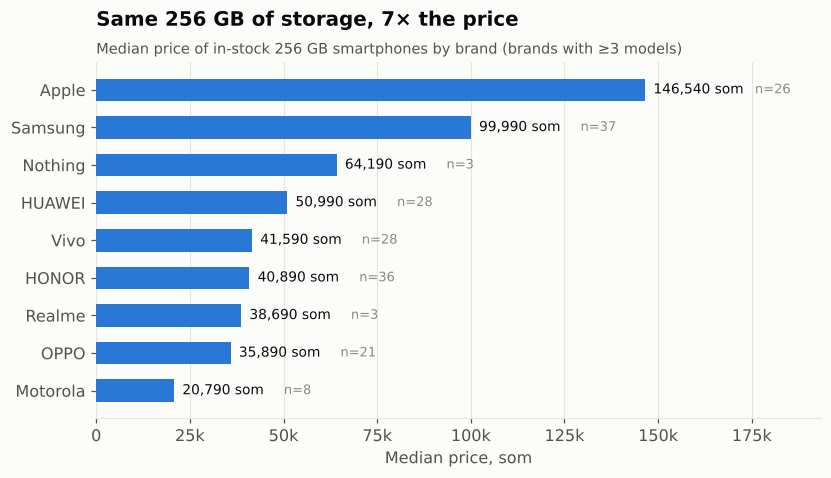

storage_gb,32.0,64.0,128.0,256.0,512.0,"1,024.0","2,048.0"
brand,,,,,,,
Apple,"28,290.0","30,190.0","98,540.0","146,540.0","187,590.0","240,790.0","320,590.0"
HONOR,NaN,"14,190.0","24,590.0","40,890.0","81,190.0",NaN,NaN
HUAWEI,NaN,NaN,"18,890.0","50,990.0","75,490.0",NaN,NaN
Motorola,NaN,NaN,NaN,"20,790.0","48,690.0",NaN,NaN
Nothing,NaN,NaN,NaN,"64,190.0","113,290.0",NaN,NaN
OPPO,NaN,"16,890.0","22,690.0","35,890.0","61,390.0",NaN,NaN
OnePlus,NaN,NaN,NaN,"50,990.0","116,290.0",NaN,NaN
Realme,NaN,NaN,"12,340.0","38,690.0","52,890.0",NaN,NaN
Samsung,NaN,"18,440.0","32,090.0","99,990.0","145,290.0",NaN,NaN


In [10]:
charts.phone_brands(df); plt.show()
ph = df[(df.category_en == 'Smartphones') & df.in_stock & (df.product_type == 'Single')]
ph.pivot_table(index='brand', columns='storage_gb', values='price', aggfunc='median').loc[
    lambda t: t.notna().sum(axis=1) >= 2].round(-1)

In [11]:
# same configuration, different brands: 8 GB RAM / 256 GB storage
ph[(ph.ram_gb == 8) & (ph.storage_gb == 256)].groupby('brand')['price'].agg(['size', 'median', 'min', 'max']).sort_values('median')

,size,median,min,max
brand,,,,
Motorola,7,"20,790.0","16,990.0","75,490.0"
HUAWEI,7,"28,290.0","22,690.0","35,890.0"
Nothing,1,"33,090.0","33,090.0","33,090.0"
OPPO,17,"35,890.0","25,490.0","62,290.0"
Realme,3,"38,690.0","23,290.0","38,690.0"
Samsung,16,"43,390.0","31,790.0","92,490.0"
HONOR,19,"45,290.0","29,290.0","71,690.0"
Vivo,12,"49,140.0","24,590.0","81,190.0"
OnePlus,2,"50,990.0","50,990.0","50,990.0"


**Finding.** For the same 256 GB of storage the median Apple phone costs **146.5k som**, Samsung 100k, and Chinese brands (HONOR, Vivo, OPPO) 36–42k. Motorola's median is 20.8k, **7× less than Apple**. Storage alone does not explain price: brand and model line do. Within one brand, storage tiers stack up fast: the median iPhone goes from ~99k (128 GB) to ~147k (256 GB) to ~188k (512 GB), mixing model generations.

## 6. Laptops

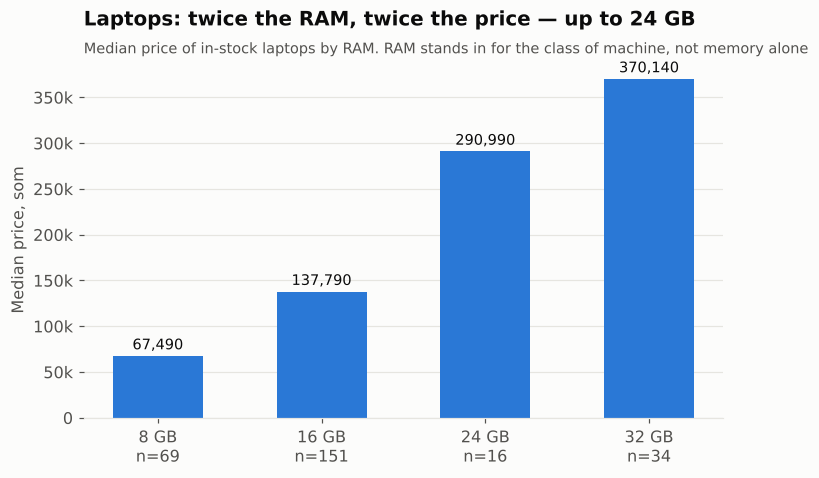

,size,median,min,max
laptop_class,,,,
Для работы и учебы,73,"58,490.0","35,890.0","163,090.0"
Ультрабуки,54,"120,690.0","66,190.0","505,490.0"
Для игр и продакшена,89,"194,790.0","83,090.0","860,790.0"
Apple MacBook,72,"197,290.0","73,590.0","657,590.0"


In [12]:
charts.laptop_ram(df); plt.show()
lp = df[(df.category_en == 'Laptops') & df.in_stock]
lp.groupby('laptop_class')['price'].agg(['size', 'median', 'min', 'max']).sort_values('median')

**Finding.** Median price doubles from 8 to 16 GB RAM (67k → 138k) and again to 24 GB (291k). RAM here is a proxy for the class of machine (office → gaming/creator → workstation), not the cost of memory. MacBooks and gaming laptops sit at the same median (~195k), work-and-study laptops at 58k.

## 7. Reviews and ratings

In [13]:
rated = df[df.reviews > 0]
print(f'Listings with at least one review: {len(rated) / len(df):.0%}')
print(f'Of those, rated 5 stars: {(rated.rating == 5).mean():.1%}')
df.nlargest(10, 'reviews')[['category_en', 'name', 'reviews', 'price', 'in_stock']]

Listings with at least one review: 36%
Of those, rated 5 stars: 98.6%


,category_en,name,reviews,price,in_stock
1833,Washing machines,Стиральная машина ARG JG60-A112VE,1814,"19,890.0",True
2,Smartphones,Смартфон Apple iPhone 15 6/128GB Black,1103,"78,090.0",True
1834,Washing machines,Стиральная машина LG F2Y1NS3W,722,"33,090.0",True
1837,Washing machines,Стиральная машина ARG JG70-A112VE,701,"21,690.0",True
1706,Fridges,Холодильник Indesit DS4180W,568,"33,090.0",True
138,Smartphones,Смартфон Apple iPhone 14 6/128GB Midnight,559,"66,090.0",True
1841,Washing machines,Стиральная машина ARG JG60-A112VE B,512,"21,690.0",True
1116,Headphones,TWS Наушники Samsung Galaxy Buds Core SM-R410N...,508,"4,890.0",True
1441,Tablets,"Планшет Apple iPad 11"" (2025) 6/128GB Wi-Fi Si...",409,"56,490.0",True
1843,Washing machines,Стиральная машина ARG JG80-A212VEG,409,"31,190.0",True


**Finding.** The star rating carries no information: 98.6% of reviewed products show 5 stars. **Review count** is the useful signal of what people buy. The most reviewed products are budget appliances (ARG washing machine at ~20k som, 1,814 reviews) and older iPhones (iPhone 15 and 14), not flagships.

## 8. Conclusions

1. **40% of listings are out of stock**, all promo bundles included. Any price comparison has to filter by availability first.
2. **Discounts are a category strategy:** appliances are discounted often (washers 49%, fridges 36%), laptops almost never (2%); headphones get the deepest cuts.
3. **Brand is the biggest driver of smartphone price:** a 256 GB phone ranges from ~21k (Motorola) to ~147k som (Apple), a 7× spread for the same storage.
4. **Stars are useless, review counts are not:** shoppers mostly review cheap appliances and previous-generation iPhones.

**Limitations.** One-day snapshot; the catalog only shows the cheapest configuration price per card; spec lines on cards are short, so some features are missing for some products; medians for brands with few models (n < 5) are indicative only.

**Next steps.** Run the scraper daily to track price changes and test whether "old prices" are real, and add product pages for full specs.